# Weight profiles

Run all cells with the `silscore` environment; the included caches are sufficient.

Generated from [nb4_weight_profiles.py](nb4_weight_profiles.py).

In [1]:
"""Cached positional and stacking profiles for the main and supplement figures.

Read the canonical profile CSV.
"""
from __future__ import annotations

import csv
from pathlib import Path

import matplotlib.pyplot as plt
from IPython.display import Image
import numpy as np

def _resolve_root() -> Path:
    file_name = globals().get("__file__")
    if file_name:
        return Path(file_name).resolve().parents[1]
    cwd = Path.cwd().resolve()
    if (cwd / "data" / "cache").is_dir():
        return cwd
    if cwd.name == "notebooks" and (cwd.parent / "data" / "cache").is_dir():
        return cwd.parent
    raise RuntimeError("cannot resolve Silscore root from __file__ or cwd")


ROOT = _resolve_root()
CSV = ROOT / "data" / "cache" / "potency_weight_profiles_v1.csv"

FIG_W = 402 / 72  # PDF points converted to inches.
FS_TICK, FS_LABEL, FS_TITLE, FS_LEGEND = 8.0, 9.0, 8.0, 8.0
COLORS = {"Huesken": "#2F67B2", "Mixset": "#8B5FBF", "Taka": "#269E75",
          "Human-489": "#D58B32", "Rodent-489": "#C44E52"}
REGIONS = [
    (0.5, 1.5, "anchor", "#ECECEC"),
    (1.5, 8.5, "seed", "#FFF3CD"),
    (8.5, 12.5, "central", "#DCEAF7"),
    (12.5, 16.5, "3' supplementary", "#DDEEDC"),
    (16.5, 19.5, "tail", "#ECECEC"),
]


def dataset_label(name: str) -> str:
    """Map upstream CSV identifiers to display names."""
    return "Katoh–Suzuki" if name == "Taka" else name


def read_data() -> dict[tuple[str, str, str, str], dict]:
    if not CSV.exists():
        raise FileNotFoundError(f"missing {CSV}: run python scripts/reproduce.py --overwrite")
    with CSV.open(newline="") as fh:
        rows = list(csv.DictReader(fh))
    groups = {}
    for r in rows:
        key = (r["dataset"], r["model"], r["scale"], r["coordinate"])
        groups.setdefault(key, []).append(r)
    for key, vals in groups.items():
        vals.sort(key=lambda r: int(r["index"]))
        groups[key] = {
            "x": np.asarray([int(r["index"]) for r in vals]),
            "estimate": np.asarray([float(r["estimate"]) for r in vals]),
            "low": np.asarray([float(r["ci_low"]) for r in vals]),
            "high": np.asarray([float(r["ci_high"]) for r in vals]),
            "B": {int(r["B"]) for r in vals},
            "n": {int(r["n"]) for r in vals},
        }
    return groups


def shade_regions(ax, ymax: float, labels: bool = True) -> None:
    for x0, x1, name, color in REGIONS:
        ax.axvspan(x0, x1, color=color, alpha=0.62, lw=0, zorder=-3)
        if labels:
            ax.text((x0 + x1) / 2, ymax, name, ha="center", va="top",
                    fontsize=6.4, color="0.32")


def plot_profile(ax, data: dict, label: str, color: str, marker: str = "o",
          linestyle: str = "-", zorder: int = 3, x_offset: float = 0.0) -> None:
    x = data["x"].astype(float) + x_offset
    y, lo, hi = data["estimate"], data["low"], data["high"]
    ax.vlines(x, lo, hi, color=color, linewidth=0.65, alpha=0.62, zorder=zorder - 2)
    ax.hlines(lo, x - 0.075, x + 0.075, color=color, linewidth=0.65,
              alpha=0.62, zorder=zorder - 2)
    ax.hlines(hi, x - 0.075, x + 0.075, color=color, linewidth=0.65,
              alpha=0.62, zorder=zorder - 2)
    ax.plot(x, y, label=label, color=color, marker=marker, markersize=3.2,
            markerfacecolor="white", markeredgewidth=0.9, linewidth=1.2,
            linestyle=linestyle, zorder=zorder)


def format_axes(ax, *, ylabel: str, title: str | None = None, n_pos: int = 19,
              region_labels: bool = False, position_ticks: bool = True) -> None:
    ax.axhline(0, color="0.45", lw=0.8, zorder=0)
    ax.set_xlim(0.5, n_pos + 0.5)
    if position_ticks:
        ax.set_xticks(np.arange(1, n_pos + 1))
    ax.tick_params(labelsize=FS_TICK, length=2.5)
    ax.set_xlabel("guide position" if n_pos == 19 else "dinucleotide step", fontsize=FS_LABEL)
    ax.set_ylabel(ylabel, fontsize=FS_LABEL)
    ax.grid(axis="y", alpha=0.18, zorder=-2)
    for position in range(1, n_pos + 1):
        ax.axvline(position, color="0.55", lw=0.45, alpha=0.16, zorder=-2)
    if title:
        ax.set_title(title, loc="left", fontsize=FS_TITLE, pad=5)
    if n_pos == 19:
        ymin, ymax = ax.get_ylim()
        padding = 0.075 * (ymax - ymin)
        ax.set_ylim(ymin, ymax + padding)
        shade_regions(ax, ymax + 0.8 * padding, labels=region_labels)


def main_profiles() -> int:
    data = read_data()
    keys = [(name, "full", "per_sd_efficacy", "W")
              for name in ("Huesken", "Mixset", "Taka")]
    missing = [k for k in keys if k not in data]
    if missing:
        raise ValueError(f"profiles missing from CSV: {missing}")

    fig, ax = plt.subplots(figsize=(FIG_W, 3.25), dpi=300)
    for (name, marker), offset in zip(
            (("Huesken", "o"), ("Mixset", "s"), ("Taka", "^")),
            (-0.12, 0.0, 0.12)):
        plot_profile(ax, data[(name, "full", "per_sd_efficacy", "W")],
              dataset_label(name), COLORS[name],
              marker, x_offset=offset)
    format_axes(ax, ylabel="standardised nucleotide weight $W_i$\n(SD per kcal/mol)",
              region_labels=True)
    ax.legend(frameon=False, fontsize=FS_LEGEND, ncol=3, loc="lower left",
              bbox_to_anchor=(0.0, 1.005), borderaxespad=0)
    fig.subplots_adjust(left=0.145, right=0.985, bottom=0.17, top=0.86)

    out = ROOT / "output" / "figures"
    out.mkdir(parents=True, exist_ok=True)
    for extension in ("pdf", "png"):
        fig.savefig(out / f"fig_weight_profiles.{extension}", dpi=300)
    plt.close(fig)
    print(f"wrote {out}/fig_weight_profiles.pdf and .png")
    return 0

In [2]:
MODELS = (
    ("physics", "Thermo-only", "#777777", "s", "-"),
    ("u1", "Thermo+U1", "#7EA6D8", "o", "-"),
    ("full", "Silscore", "#245AA5", "o", "--"),
)


def model_panel(ax, data, dataset: str, letter: str, title: str | None = None) -> None:
    shown_models = MODELS[:1] if dataset in {"Mixset", "Taka"} else MODELS
    offsets = [0.0] if len(shown_models) == 1 else [-0.12, 0.0, 0.12]
    for (model, label, color, marker, linestyle), offset in zip(shown_models, offsets):
        plot_profile(ax, data[(dataset, model, "per_sd_efficacy", "W")], label,
              color, marker, linestyle, zorder=3 if model != "full" else 4,
              x_offset=offset)
    display_name = title or dataset_label(dataset)
    format_axes(ax, ylabel="standardised $W_i$", title=f"{letter}  {display_name}",
              position_ticks=False)
    ax.legend(frameon=False, fontsize=6.2, ncol=1, loc="lower left",
              borderaxespad=0.4, handlelength=1.8)


def main_profiles_supplement() -> int:
    data = read_data()
    required = []
    for name in ("Huesken", "Mixset", "Taka", "Rodent-489"):
        required.extend((name, m, "per_sd_efficacy", "W") for m, *_ in MODELS)
    required.extend((name, "physics", "per_sd_efficacy", "W")
                     for name in ("Human-489", "Rodent-489"))
    required.extend((name, "full", "per_sd_efficacy", "W")
                     for name in ("Human-489", "Rodent-489"))
    missing = [k for k in required if k not in data]
    if missing:
        raise ValueError(f"profiles missing from CSV: {missing}")

    fig, axes = plt.subplots(3, 2, figsize=(FIG_W, 7.55), dpi=300)

    ax = axes[0, 0]
    styles = {
        "Huesken": (COLORS["Huesken"], "o", "-", "Huesken"),
        "Mixset": (COLORS["Mixset"], "s", "-", "Mixset"),
        "Taka": (COLORS["Taka"], "^", "-", "KS"),
        "Human-489": (COLORS["Human-489"], "D", "--", "human inserts ($n=489$)"),
        "Rodent-489": (COLORS["Rodent-489"], "v", "--", "rodent inserts ($n=489$)"),
    }
    for (name, (color, marker, linestyle, label)), offset in zip(
            styles.items(), (-0.24, -0.12, 0.0, 0.12, 0.24)):
        plot_profile(ax, data[(name, "physics", "per_sd_efficacy", "W")], label,
              color, marker, linestyle, x_offset=offset)
    format_axes(ax, ylabel="standardised $W_i$", title="A  Thermo-only profiles",
              position_ticks=False)
    ax.legend(frameon=False, fontsize=5.5, ncol=2, loc="lower left",
              borderaxespad=0.4, handlelength=1.6)

    model_panel(axes[0, 1], data, "Huesken", "B")
    model_panel(axes[1, 0], data, "Mixset", "C")
    model_panel(axes[1, 1], data, "Taka", "D", "KS")
    model_panel(axes[2, 0], data, "Rodent-489", "E", "Rodent inserts ($n=489$)")

    # Compare profiles at matched training-set sizes.
    ax = axes[2, 1]
    for (name, label, marker), offset in zip(
            (("Huesken", "Huesken (all)", "o"),
             ("Human-489", "human inserts ($n=489$)", "D"),
             ("Rodent-489", "rodent inserts ($n=489$)", "v")),
            (-0.12, 0.0, 0.12)):
        plot_profile(ax, data[(name, "full", "per_sd_efficacy", "W")], label,
              COLORS[name], marker, x_offset=offset)
    format_axes(ax, ylabel="standardised $W_i$", title="F  Huesken training samples",
              position_ticks=False)
    ax.legend(frameon=False, fontsize=5.9, ncol=1, loc="lower left", borderaxespad=0.4)

    for ax in axes.flat:
        ax.tick_params(axis="x", labelsize=7)
    fig.subplots_adjust(left=0.105, right=0.985, bottom=0.065, top=0.970,
                        wspace=0.31, hspace=0.38)

    out = ROOT / "output" / "figures"
    for extension in ("pdf", "png"):
        fig.savefig(out / f"fig_weight_profiles_supplement.{extension}", dpi=300)
    plt.close(fig)
    print(f"wrote {out}/fig_weight_profiles_supplement.pdf and .png")
    return 0

In [3]:
def main_stacks_supplement() -> int:
    data = read_data()
    keys = [(name, "full", "per_sd_efficacy", "w")
              for name in ("Huesken", "Mixset", "Taka")]
    missing = [k for k in keys if k not in data]
    if missing:
        raise ValueError(f"stacking weights missing from CSV: {missing}")

    fig, ax = plt.subplots(figsize=(FIG_W, 3.0), dpi=300)
    for (name, marker), offset in zip(
            (("Huesken", "o"), ("Mixset", "s"), ("Taka", "^")),
            (-0.12, 0.0, 0.12)):
        plot_profile(ax, data[(name, "full", "per_sd_efficacy", "w")],
              "KS" if name == "Taka" else dataset_label(name),
              COLORS[name], marker, x_offset=offset)
    format_axes(ax, ylabel="standardised stacking weight $w_i$\n(SD per kcal/mol)",
              n_pos=18)
    ax.legend(frameon=False, fontsize=8, ncol=3, loc="lower left",
              bbox_to_anchor=(0.0, 1.005), borderaxespad=0)
    fig.subplots_adjust(left=0.145, right=0.985, bottom=0.18, top=0.86)

    out = ROOT / "output" / "figures"
    for extension in ("pdf", "png"):
        fig.savefig(out / f"fig_weight_stacks_supplement.{extension}", dpi=300)
    plt.close(fig)
    print(f"wrote {out}/fig_weight_stacks_supplement.pdf and .png")
    return 0

wrote ./output/figures/fig_weight_profiles.pdf and .png


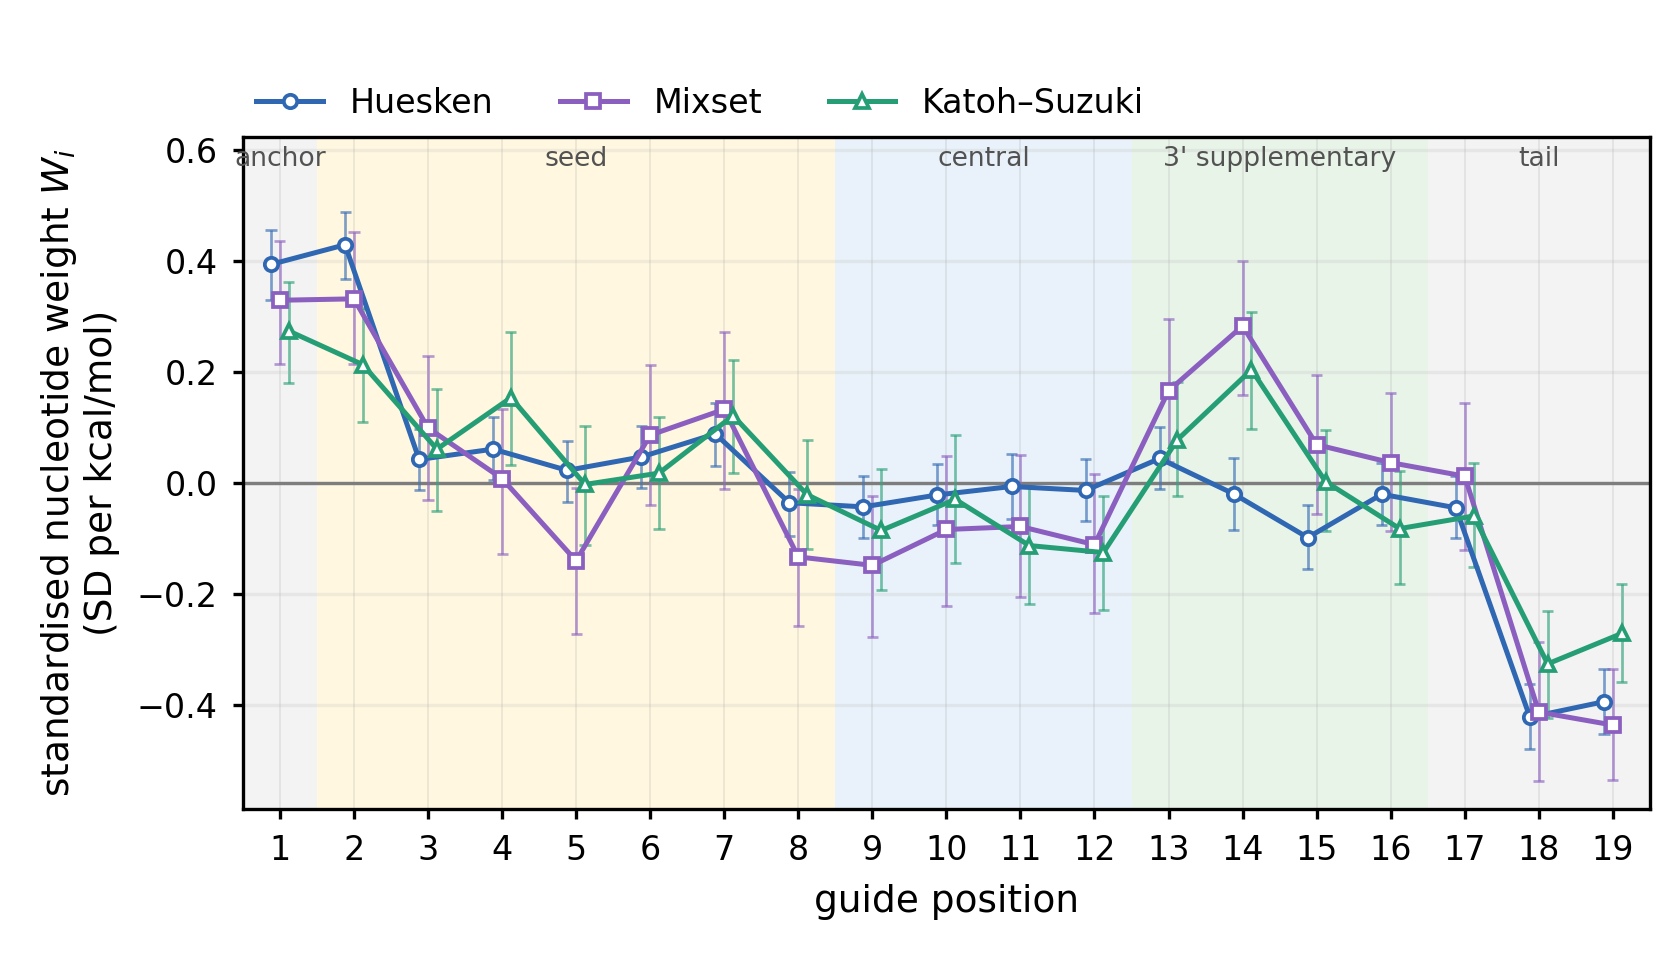

In [4]:
main_profiles()
Image(filename=str(ROOT / "output" / "figures" / "fig_weight_profiles.png"))

wrote ./output/figures/fig_weight_profiles_supplement.pdf and .png


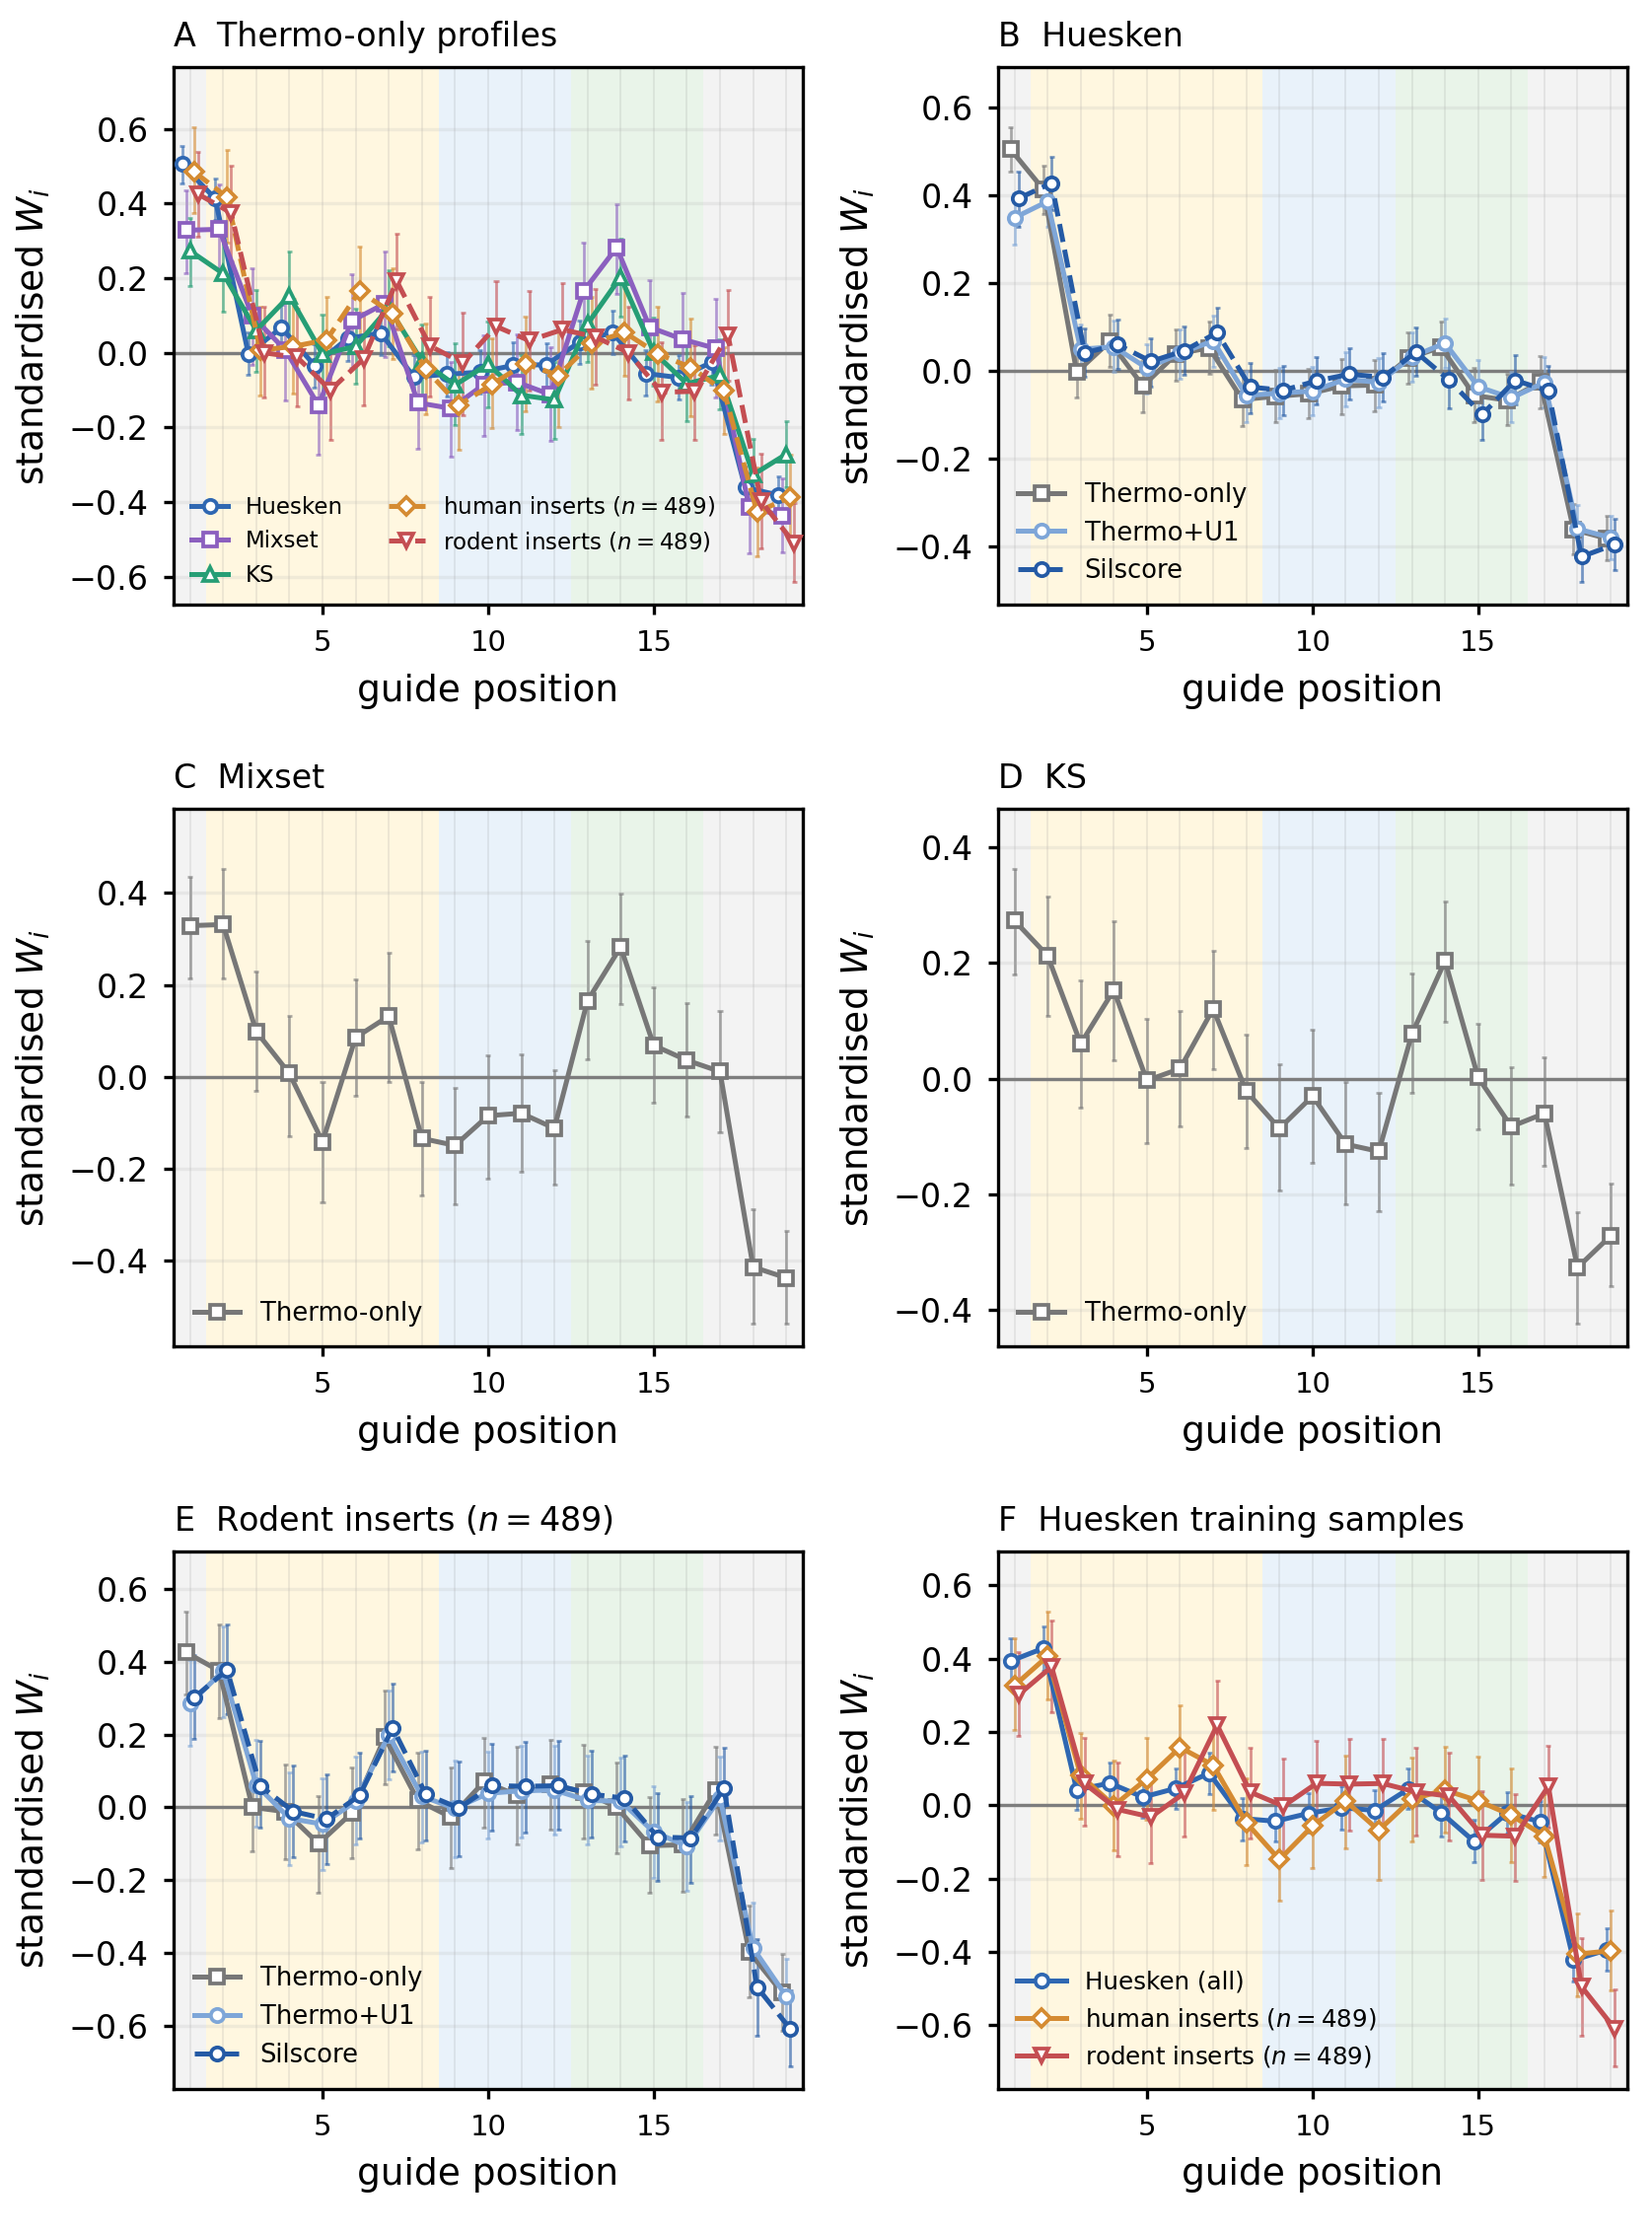

In [5]:
main_profiles_supplement()
Image(filename=str(ROOT / "output" / "figures" / "fig_weight_profiles_supplement.png"))

wrote ./output/figures/fig_weight_stacks_supplement.pdf and .png


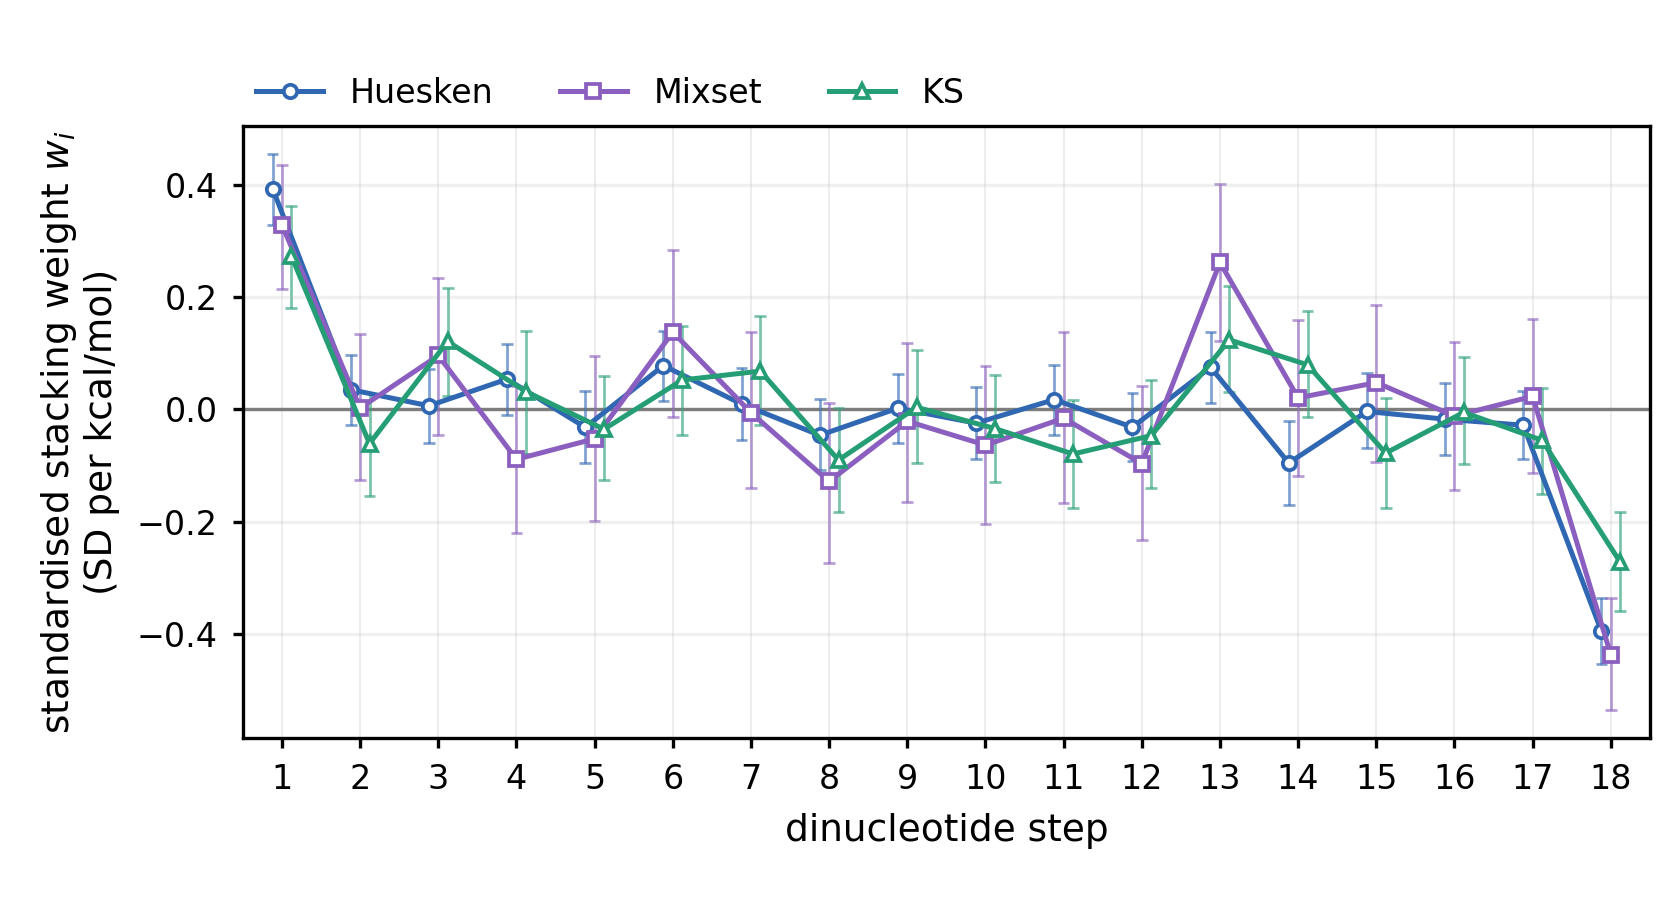

In [6]:
main_stacks_supplement()
Image(filename=str(ROOT / "output" / "figures" / "fig_weight_stacks_supplement.png"))